In [193]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
import json
import time

import xgboost as xgb
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, StratifiedKFold, permutation_test_score, GridSearchCV
from sklearn.metrics import classification_report, recall_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,make_scorer,balanced_accuracy_score, f1_score
import matplotlib.pyplot as plt

data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'
refrence_dir = data_dir + '/CHCH_v3_reference/'
reference_mask_dir = refrence_dir + 'processed{}/'
model_save_dir = refrence_dir + 'models/'

In [137]:
infile = refrence_dir + 'peaks_training_df.csv'
peaks_df = pd.read_csv(infile, index_col=[0]) 
print('  <--- ' + infile)


  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/peaks_training_df.csv


In [138]:
## Filtering

peaks_df = peaks_df.dropna() # removes NaNs (e.g. no temperature data, so bad classification)

# Exclude case study dates from training dataset                           
exclusion_dates = [
    20210518,
    20210605,
    ]
                     
peaks_df_eval = peaks_df[peaks_df['date'].isin(exclusion_dates)]
peaks_df = peaks_df[~peaks_df['date'].isin(exclusion_dates)]

# Removing peaks with unknown and undetermined reference mask classification
peaks_df = peaks_df[peaks_df['unan_target'] == 0]
peaks_df = peaks_df[peaks_df['undet_target'] == 0]

peaks_df = peaks_df.reset_index(drop=True)

peaks_df['target'] = peaks_df[['wlwc_target','slwc_target','mpc_target', 'ic_target']].idxmax(axis=1)
cat_type = CategoricalDtype(categories=['wlwc_target','slwc_target','mpc_target', 'ic_target'], ordered=True)
peaks_df['target_int']= peaks_df['target'].astype(cat_type).cat.codes  

# Defining groups for the different training datasets        
groups = peaks_df['date'].astype('str').str[:-2]

In [139]:
peaks_df_eval = peaks_df_eval[peaks_df_eval['unan_target'] == 0]
peaks_df_eval = peaks_df_eval[peaks_df_eval['undet_target'] == 0]
peaks_df_eval = peaks_df_eval.reset_index(drop=True)
peaks_df_eval['target'] = peaks_df_eval[['wlwc_target','slwc_target','mpc_target', 'ic_target']].idxmax(axis=1)
cat_type = CategoricalDtype(categories=['wlwc_target','slwc_target','mpc_target', 'ic_target'], ordered=True)
peaks_df_eval['target_int']= peaks_df_eval['target'].astype(cat_type).cat.codes  


In [142]:
peaks_df

,date,peak_time_idx,peak_alt_idx,peak_magnitude,peak_width,peak_width_height,peak_prominence,peak_alt,num_peaks,peak_order,peak_temp,wlwc_target,slwc_target,slcc_target,mpc_target,ic_target,undet_target,unan_target,target,target_int
0,20210514,43,202,0.000025,5.021346,0.000013,0.000025,10.125,1,0,-53.570575,0,0,0,0,1,0,0,ic_target,3
1,20210514,44,202,0.000022,5.433444,0.000011,0.000023,10.125,1,0,-53.569078,0,0,0,0,1,0,0,ic_target,3
2,20210514,50,195,0.000020,18.462372,0.000010,0.000020,9.775,1,0,-52.376248,0,0,0,0,1,0,0,ic_target,3
3,20210514,51,192,0.000023,16.217988,0.000012,0.000023,9.625,1,0,-51.669931,0,0,0,0,1,0,0,ic_target,3
4,20210514,52,192,0.000020,1.588991,0.000020,0.000001,9.625,2,0,-51.700269,0,0,0,0,1,0,0,ic_target,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35856,20220120,283,62,0.000199,1.804206,0.000099,0.000199,3.125,1,0,-4.375582,0,1,1,0,0,0,0,slwc_target,1
35857,20220120,286,228,0.000026,3.522913,0.000013,0.000026,11.425,1,0,-54.901438,0,0,0,0,1,0,0,ic_target,3
35858,20220121,35,53,0.000070,1.861522,0.000035,0.000070,2.675,1,0,-0.646539,0,1,1,0,0,0,0,slwc_target,1
35859,20220121,36,52,0.000105,1.742200,0.000052,0.000105,2.625,1,0,-0.414722,0,0,1,1,0,0,0,mpc_target,2


In [51]:
## Select input and target variables for model training
input_vars = [
    'peak_magnitude', 
    'peak_width',
    'peak_width_height',
    'peak_prominence',
    'peak_alt',
    'num_peaks',
    'peak_order',
    'peak_temp',
    ]

input = peaks_df[input_vars]                 


### Binary classification - target WLWC

In [62]:
# Selecting target for binary classification
target_vars = 'wlwc_target'

target = peaks_df[target_vars]    
sgkf = StratifiedGroupKFold(n_splits=3)

cv = sgkf
model = xgb.XGBClassifier(objective='binary:logistic',
                      booster='gbtree', n_jobs=-1,
                      use_label_encoder=False,verbosity=0)
model.fit(input, target)
print(classification_report(target, model.predict(input)))
print(confusion_matrix(target, model.predict(input),normalize='all'))
print()
scores_recall = cross_val_score(model, input, target, cv=cv, scoring='recall', groups=groups)

print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
print()

for idx, (train, test) in enumerate(cv.split(input, target,groups=groups)):
    print('CV fold', idx)
    print('Train dataset class ratio = {:.3f}'.format(target[train].mean()))
    print('Test dataset class ratio = {:.3f}'.format(target[test].mean()))
    print('Train/Test dataset size = {}/{}'.format(len(train),len(test)))

    model.fit(input.iloc[train], target[train])
    Y_pred = model.predict(input.iloc[test])
    print(idx, classification_report(target[test], Y_pred))

    print(confusion_matrix(target[test], Y_pred,normalize='all'))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     16039
           1       1.00      1.00      1.00     19822

    accuracy                           1.00     35861
   macro avg       1.00      1.00      1.00     35861
weighted avg       1.00      1.00      1.00     35861

[[0.44725468 0.        ]
 [0.         0.55274532]]

[0.99878123 1.         0.99821429] 0.999, 0.001

CV fold 0
Train dataset class ratio = 0.522
Test dataset class ratio = 0.627
Train/Test dataset size = 25396/10465
0               precision    recall  f1-score   support

           0       1.00      1.00      1.00      3901
           1       1.00      1.00      1.00      6564

    accuracy                           1.00     10465
   macro avg       1.00      1.00      1.00     10465
weighted avg       1.00      1.00      1.00     10465

[[0.37152413 0.00124224]
 [0.00076445 0.62646918]]
CV fold 1
Train dataset class ratio = 0.554
Test dataset class ratio = 0.550


### Binary classification - target SLWC

In [29]:
# Selecting target for binary classification
target_vars = 'slwc_target'

target = peaks_df[target_vars]    
sgkf = StratifiedGroupKFold(n_splits=3)

cv = sgkf
model = xgb.XGBClassifier(objective='binary:logistic',
                      booster='gbtree', n_jobs=-1,
                      use_label_encoder=False,verbosity=0)
model.fit(input, target)
print(classification_report(target, model.predict(input)))
print(confusion_matrix(target, model.predict(input),normalize='all'))
print()
scores_recall = cross_val_score(model, input, target, cv=cv, scoring='recall', groups=groups)

print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
print()

for idx, (train, test) in enumerate(cv.split(input, target,groups=groups)):
    print('CV fold', idx)
    print('Train dataset class ratio = {:.3f}'.format(target[train].mean()))
    print('Test dataset class ratio = {:.3f}'.format(target[test].mean()))
    print('Train/Test dataset size = {}/{}'.format(len(train),len(test)))

    model.fit(input.iloc[train], target[train])
    Y_pred = model.predict(input.iloc[test])
    print(idx, classification_report(target[test], Y_pred))

    print(confusion_matrix(target[test], Y_pred,normalize='all'))

              precision    recall  f1-score   support

           0       0.99      0.95      0.97     28878
           1       0.85      0.97      0.90      7889

    accuracy                           0.96     36767
   macro avg       0.92      0.96      0.94     36767
weighted avg       0.96      0.96      0.96     36767

[[0.74738216 0.03805043]
 [0.00677238 0.20779503]]

[0.91547708 0.85303514 0.90929122] 0.893, 0.028

CV fold 0
Train dataset class ratio = 0.217
Test dataset class ratio = 0.211
Train/Test dataset size = 24130/12637
0               precision    recall  f1-score   support

           0       0.98      0.92      0.95      9975
           1       0.76      0.92      0.83      2662

    accuracy                           0.92     12637
   macro avg       0.87      0.92      0.89     12637
weighted avg       0.93      0.92      0.92     12637

[[0.72746696 0.06188178]
 [0.01780486 0.1928464 ]]
CV fold 1
Train dataset class ratio = 0.219
Test dataset class ratio = 0.206


### Binary classification - target SLCC

In [31]:
# Selecting target for binary classification
target_vars = 'slcc_target'

target = peaks_df[target_vars]    
sgkf = StratifiedGroupKFold(n_splits=3)

cv = sgkf
model = xgb.XGBClassifier(objective='binary:logistic',
                      booster='gbtree', n_jobs=-1,
                      use_label_encoder=False,verbosity=0)
model.fit(input, target)
print(classification_report(target, model.predict(input)))
print(confusion_matrix(target, model.predict(input),normalize='all'))
print()
scores_recall = cross_val_score(model, input, target, cv=cv, scoring='recall', groups=groups)

print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
print()

for idx, (train, test) in enumerate(cv.split(input, target,groups=groups)):
    print('CV fold', idx)
    print('Train dataset class ratio = {:.3f}'.format(target[train].mean()))
    print('Test dataset class ratio = {:.3f}'.format(target[test].mean()))
    print('Train/Test dataset size = {}/{}'.format(len(train),len(test)))

    model.fit(input.iloc[train], target[train])
    Y_pred = model.predict(input.iloc[test])
    print(idx, classification_report(target[test], Y_pred))

    print(confusion_matrix(target[test], Y_pred,normalize='all'))

              precision    recall  f1-score   support

           0       0.99      0.98      0.99     26725
           1       0.96      0.98      0.97     10042

    accuracy                           0.98     36767
   macro avg       0.97      0.98      0.98     36767
weighted avg       0.98      0.98      0.98     36767

[[0.71433623 0.01253842]
 [0.00590203 0.26722333]]

[0.94938165 0.94398093 0.94764724] 0.947, 0.002

CV fold 0
Train dataset class ratio = 0.272
Test dataset class ratio = 0.275
Train/Test dataset size = 24130/12637
0               precision    recall  f1-score   support

           0       0.98      0.97      0.97      9160
           1       0.92      0.95      0.93      3477

    accuracy                           0.96     12637
   macro avg       0.95      0.96      0.95     12637
weighted avg       0.96      0.96      0.96     12637

[[0.70064097 0.02421461]
 [0.01392736 0.26121706]]
CV fold 1
Train dataset class ratio = 0.270
Test dataset class ratio = 0.280


### Multiclass classification: WLWC, SLWC, MPC and IC

0.9165667438164022
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19824
           1       0.77      0.97      0.86      7889
           2       0.46      0.01      0.01      2153
           3       0.89      0.91      0.90      5995

    accuracy                           0.92     35861
   macro avg       0.78      0.72      0.69     35861
weighted avg       0.90      0.92      0.89     35861

[[9.96368039e-01 3.48062954e-03 0.00000000e+00 1.51331719e-04]
 [3.80276334e-04 9.66028647e-01 1.14082900e-03 3.24502472e-02]
 [0.00000000e+00 7.87738040e-01 5.57361821e-03 2.06688342e-01]
 [1.66805671e-04 8.42368641e-02 8.34028357e-04 9.14762302e-01]]

              precision    recall  f1-score   support

           0       1.00      0.99      0.99        79
           1       0.74      0.97      0.84       217
           2       0.00      0.00      0.00        43
           3       0.92      0.85      0.88       285

    accuracy        

/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_

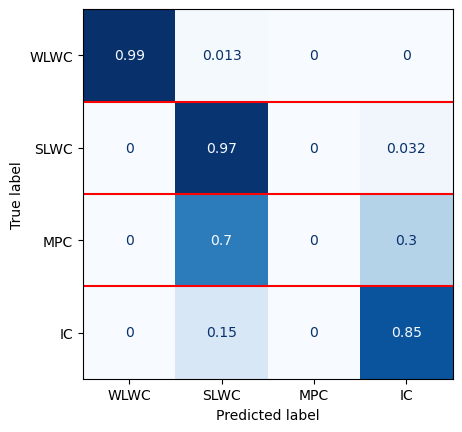

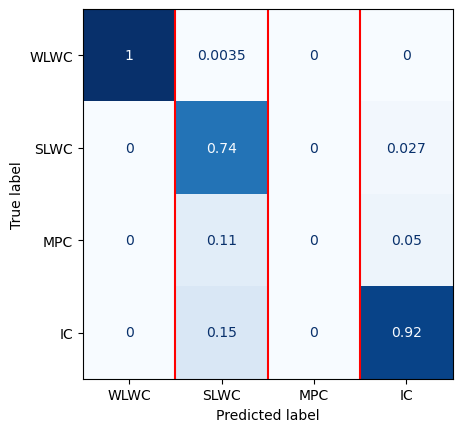

In [163]:
target =  peaks_df['target_int'] 

sgkf = StratifiedGroupKFold(n_splits=3)
cv = sgkf

model = xgb.XGBClassifier(objective='multi:softprob',
                      booster='gbtree', n_jobs=-1,
                      use_label_encoder=False,verbosity=0)

params_multi = {'learning_rate': 0.01, 'max_depth': 3}
model.set_params(**params_multi)


model.fit(input, target)

print(accuracy_score(target, model.predict(input)))
print(classification_report(target, model.predict(input)))
print(confusion_matrix(target, model.predict(input),normalize='true'))
print()


input_eval = peaks_df_eval[input_vars]
target_eval =  peaks_df_eval['target_int'] 
print(classification_report(target_eval, model.predict(input_eval)))

class_names = ['WLWC','SLWC','MPC', 'IC']

disp_true = ConfusionMatrixDisplay.from_estimator(
        model,
        input_eval,
        target_eval,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        model,
        input_eval,
        target_eval,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

# scores_recall = cross_val_score(model, input, target, cv=cv, groups=groups)
# print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
# print()

# for idx, (train, test) in enumerate(cv.split(input, target,groups=groups)):
#     print('CV fold', idx)
#     print('Train dataset class ratio = {:.3f}'.format(target[train].mean()))
#     print('Test dataset class ratio = {:.3f}'.format(target[test].mean()))
#     print('Train/Test dataset size = {}/{}'.format(len(train),len(test)))

#     model.fit(input.iloc[train], target[train])
#     Y_pred = model.predict(input.iloc[test])
#     print(idx, classification_report(target[test], Y_pred))



Starting grid search
Fitting 3 folds for each of 240 candidates, totalling 720 fits
[CV 2/3] END gamma=0, learning_rate=0.01, max_depth=3, reg_lambda=0;, score=(train=0.001, test=0.000) total time=   1.1s
[CV 3/3] END gamma=0, learning_rate=0.01, max_depth=3, reg_lambda=0;, score=(train=0.001, test=0.000) total time=   1.1s
[CV 1/3] END gamma=0, learning_rate=0.01, max_depth=3, reg_lambda=0;, score=(train=0.003, test=0.000) total time=   1.0s
[CV 3/3] END gamma=0, learning_rate=0.01, max_depth=3, reg_lambda=1.0;, score=(train=0.001, test=0.000) total time=   1.1s
[CV 1/3] END gamma=0, learning_rate=0.01, max_depth=3, reg_lambda=3.0;, score=(train=0.003, test=0.000) total time=   1.2s
[CV 2/3] END gamma=0, learning_rate=0.01, max_depth=3, reg_lambda=1.0;, score=(train=0.001, test=0.000) total time=   1.3s
[CV 2/3] END gamma=0, learning_rate=0.01, max_depth=3, reg_lambda=3.0;, score=(train=0.001, test=0.000) total time=   1.4s
[CV 1/3] END gamma=0, learning_rate=0.01, max_depth=3, reg_la

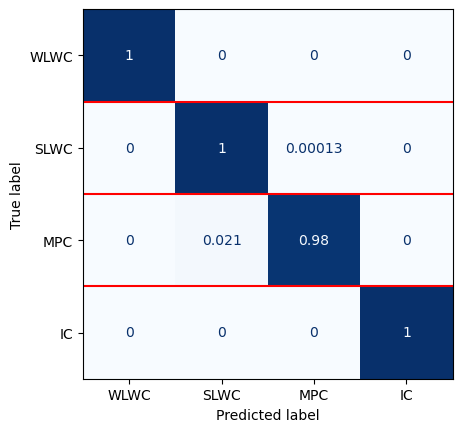

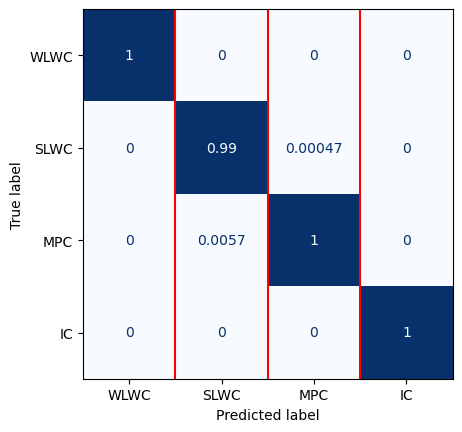

In [204]:
#### Hyperparameter search with GridCV

target =  peaks_df['target_int'] 

sgkf = StratifiedGroupKFold(n_splits=3)
cv = sgkf

model = xgb.XGBClassifier(objective='multi:softprob',
                      booster='gbtree', n_jobs=-1,
                      use_label_encoder=False,verbosity=0)

hyperparameter_space = {
                        'max_depth':[3,6,9], 
                        'learning_rate':[0.01,0.02,0.1,0.3,0.5],
                        'gamma':[0,1,3,6],
                        'reg_lambda':[0,1.0,3.0,10.0],
                        # 'scale_pos_weight':[1,3,5]
                        }

gs = GridSearchCV(model, param_grid=hyperparameter_space,verbose=4,scoring=make_scorer(recall_score,labels=[2],average='macro'),
                  n_jobs=-1, cv=cv, return_train_score=True)

print('Starting grid search')
start_time = time.time()
gs.fit(input,target,groups=groups)
print(gs.best_params_)
print(gs.best_score_)
best_model = gs.best_estimator_
print("--- %s seconds ---" % (time.time() - start_time))


# model.fit(input, target)

# best_model = model

# print(accuracy_score(target, best_model.predict(input)))
print(classification_report(target, best_model.predict(input)))
# print(confusion_matrix(target, model.predict(input),normalize='true'))
# print()

# scores_recall = cross_val_score(model, input, target, cv=cv, groups=groups)
# print(scores_recall, '{:.3f}, {:.3f}'.format(np.mean(scores_recall),np.std(scores_recall)))
# print()

class_names = ['WLWC','SLWC','MPC', 'IC']

disp_true = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        best_model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

## Evaluation of case study days
# input_eval = peaks_df_eval[input_vars]
# target_eval =  peaks_df_eval['target_int'] 
# print(classification_report(target_eval, best_model.predict(input_eval)))

# disp_true = ConfusionMatrixDisplay.from_estimator(
#         best_model,
#         input_eval,
#         target_eval,
#         display_labels=class_names,
#         cmap=plt.cm.Blues,
#         normalize='true',
#         colorbar=False
#     )

# disp_true.ax_.hlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

# disp_pred = ConfusionMatrixDisplay.from_estimator(
#         best_model,
#         input_eval,
#         target_eval,
#         display_labels=class_names,
#         cmap=plt.cm.Blues,
#         normalize='pred',
#         colorbar=False
#     )

# disp_pred.ax_.vlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')


In [208]:
# balanced_accuracy_score(target, best_model.predict(input))
# f1_score(target, best_model.predict(input), average='weighted')
recall_score(target, best_model.predict(input), average='weighted')


0.9987172694570704

In [209]:
best_model.save_model(model_save_dir+'model_005.json') 

In [187]:
## Get hyperparams for model

json.loads(best_model.get_booster().save_config())

{'learner': {'generic_param': {'device': 'cpu',
   'fail_on_invalid_gpu_id': '0',
   'n_jobs': '-1',
   'nthread': '-1',
   'random_state': '0',
   'seed': '0',
   'seed_per_iteration': '0',
   'validate_parameters': '1'},
  'gradient_booster': {'gbtree_model_param': {'num_parallel_tree': '1',
    'num_trees': '400'},
   'gbtree_train_param': {'process_type': 'default',
    'tree_method': 'auto',
    'updater': 'grow_quantile_histmaker',
    'updater_seq': 'grow_quantile_histmaker'},
   'name': 'gbtree',
   'specified_updater': False,
   'tree_train_param': {'alpha': '0',
    'cache_opt': '1',
    'colsample_bylevel': '1',
    'colsample_bynode': '1',
    'colsample_bytree': '1',
    'eta': '0.300000012',
    'gamma': '0',
    'grow_policy': 'depthwise',
    'interaction_constraints': '',
    'lambda': '0',
    'learning_rate': '0.300000012',
    'max_bin': '256',
    'max_cat_threshold': '64',
    'max_cat_to_onehot': '4',
    'max_delta_step': '0',
    'max_depth': '9',
    'max_leav

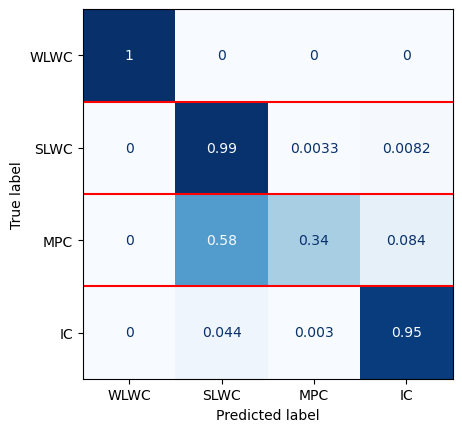

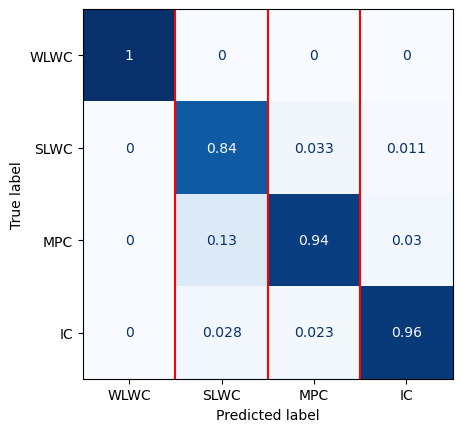

In [91]:
## Code to create confusion matrices:

class_names = ['WLWC','SLWC','MPC', 'IC']

disp_true = ConfusionMatrixDisplay.from_estimator(
        model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='true',
        colorbar=False
    )

disp_true.ax_.hlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')

disp_pred = ConfusionMatrixDisplay.from_estimator(
        model,
        input,
        target,
        display_labels=class_names,
        cmap=plt.cm.Blues,
        normalize='pred',
        colorbar=False
    )

disp_pred.ax_.vlines([0.5, 1.5, 2.5], -0.5,3.5, colors='red')